<a href="https://colab.research.google.com/github/Vivekb638/movie-recommendation-pyspark/blob/main/notebooks/07_graphx_integration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/movie-recommendation-pyspark"


Mounted at /content/drive


Create a GraphX results folder

In [2]:
import os

GRAPHX_PATH = f"{PROJECT_PATH}/graphx"

os.makedirs(GRAPHX_PATH, exist_ok=True)

print("GraphX folder:", GRAPHX_PATH)

GraphX folder: /content/drive/MyDrive/movie-recommendation-pyspark/graphx


Download the three files from GitHub

In [3]:
!wget -q -O "$GRAPHX_PATH/movie_pagerank.txt" \
https://raw.githubusercontent.com/Vivekb638/movie-recommendation-pyspark/main/graphx/results/export/movie_pagerank.txt

!wget -q -O "$GRAPHX_PATH/vertex_degrees.txt" \
https://raw.githubusercontent.com/Vivekb638/movie-recommendation-pyspark/main/graphx/results/export/vertex_degrees.txt

!wget -q -O "$GRAPHX_PATH/communities.txt" \
https://raw.githubusercontent.com/Vivekb638/movie-recommendation-pyspark/main/graphx/results/export/communities.txt

Verify the downloaded files:

In [4]:
for filename in [
    "movie_pagerank.txt",
    "vertex_degrees.txt",
    "communities.txt"
]:
    path = f"{GRAPHX_PATH}/{filename}"
    print(filename, os.path.getsize(path), "bytes")

movie_pagerank.txt 95314 bytes
vertex_degrees.txt 112237 bytes
communities.txt 138081 bytes


In [5]:
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq
!pip install -q pyspark==3.5.5

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.020s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't

In [6]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("GraphXIntegration")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

Parse PageRank

In [7]:
from pyspark.sql.functions import (
    col, regexp_extract, when, lit
)

pagerank_raw = spark.read.text(
    f"{GRAPHX_PATH}/movie_pagerank.txt"
)

movie_pagerank = pagerank_raw.select(
    regexp_extract("value", r"\((\d+),", 1)
        .cast("integer").alias("movieId"),

    regexp_extract("value", r",([^)]+)\)", 1)
        .cast("double").alias("pageRank")
)

movie_pagerank.show(10, truncate=False)
print("PageRank rows:", movie_pagerank.count())

+-------+------------------+
|movieId|pageRank          |
+-------+------------------+
|764    |1.0000000000000266|
|3652   |1.0000000000000266|
|536    |1.0000000000000266|
|1936   |1.0000000000000266|
|2416   |1.0000000000000266|
|1884   |1.0000000000000266|
|2836   |1.0000000000000266|
|3224   |1.0000000000000266|
|1888   |1.0000000000000266|
|540    |1.0000000000000266|
+-------+------------------+
only showing top 10 rows

PageRank rows: 3706


Parse vertex degrees

In [8]:
degree_raw = spark.read.text(
    f"{GRAPHX_PATH}/vertex_degrees.txt"
)

vertex_degrees = degree_raw.select(
    regexp_extract("value", r"\((\d+),", 1)
        .cast("long").alias("vertexId"),

    regexp_extract("value", r",([^)]+)\)", 1)
        .cast("integer").alias("degree")
)

vertex_degrees = (
    vertex_degrees
    .withColumn(
        "entity_type",
        when(col("vertexId") >= 1000000, lit("MOVIE"))
        .otherwise(lit("USER"))
    )
    .withColumn(
        "entity_id",
        when(
            col("entity_type") == "MOVIE",
            col("vertexId") - 1000000
        ).otherwise(col("vertexId"))
    )
)

vertex_degrees.show(10, truncate=False)
print("Degree rows:", vertex_degrees.count())

+--------+------+-----------+---------+
|vertexId|degree|entity_type|entity_id|
+--------+------+-----------+---------+
|4904    |404   |USER       |4904     |
|1084    |180   |USER       |1084     |
|1000764 |74    |MOVIE      |764      |
|1003652 |5     |MOVIE      |3652     |
|1000536 |55    |MOVIE      |536      |
|1001936 |82    |MOVIE      |1936     |
|3456    |55    |USER       |3456     |
|1002416 |354   |MOVIE      |2416     |
|1001884 |298   |MOVIE      |1884     |
|1002836 |163   |MOVIE      |2836     |
+--------+------+-----------+---------+
only showing top 10 rows

Degree rows: 9746


Parse communities

In [9]:
community_raw = spark.read.text(
    f"{GRAPHX_PATH}/communities.txt"
)

communities = community_raw.select(
    regexp_extract("value", r"\((\d+),", 1)
        .cast("long").alias("vertexId"),

    regexp_extract("value", r",([^)]+)\)", 1)
        .cast("long").alias("communityId")
)

communities = (
    communities
    .withColumn(
        "entity_type",
        when(col("vertexId") >= 1000000, lit("MOVIE"))
        .otherwise(lit("USER"))
    )
    .withColumn(
        "entity_id",
        when(
            col("entity_type") == "MOVIE",
            col("vertexId") - 1000000
        ).otherwise(col("vertexId"))
    )
)

communities.show(10, truncate=False)
print("Community rows:", communities.count())

+--------+-----------+-----------+---------+
|vertexId|communityId|entity_type|entity_id|
+--------+-----------+-----------+---------+
|4904    |2990       |USER       |4904     |
|1084    |2990       |USER       |1084     |
|1000764 |1001259    |MOVIE      |764      |
|1003652 |1001259    |MOVIE      |3652     |
|1000536 |1001259    |MOVIE      |536      |
|1001936 |1001259    |MOVIE      |1936     |
|3456    |2990       |USER       |3456     |
|1002416 |1001259    |MOVIE      |2416     |
|1001884 |1001259    |MOVIE      |1884     |
|1002836 |1001259    |MOVIE      |2836     |
+--------+-----------+-----------+---------+
only showing top 10 rows

Community rows: 9746


**Analyze the PageRank scores**

PageRank statistics

In [10]:
movie_pagerank.select("pageRank").summary().show()

+-------+------------------+
|summary|          pageRank|
+-------+------------------+
|  count|              3706|
|   mean| 1.000000000000002|
| stddev|               0.0|
|    min|1.0000000000000266|
|    25%|1.0000000000000266|
|    50%|1.0000000000000266|
|    75%|1.0000000000000266|
|    max|1.0000000000000266|
+-------+------------------+



In [11]:
movies_clean = spark.read.parquet(
    f"{PROJECT_PATH}/data/processed/movies_clean"
)

top_pagerank_movies = (
    movie_pagerank
    .join(movies_clean, "movieId", "inner")
    .orderBy(col("pageRank").desc())
)

top_pagerank_movies.select(
    "movieId", "title", "pageRank"
).show(20, truncate=False)

+-------+--------------------------------------------------------------------+------------------+
|movieId|title                                                               |pageRank          |
+-------+--------------------------------------------------------------------+------------------+
|764    |Heavy (1995)                                                        |1.0000000000000266|
|3652   |City of the Living Dead (Paura nella citt� dei morti viventi) (1980)|1.0000000000000266|
|536    |Simple Twist of Fate, A (1994)                                      |1.0000000000000266|
|1936   |Mrs. Miniver (1942)                                                 |1.0000000000000266|
|2416   |Back to School (1986)                                               |1.0000000000000266|
|1884   |Fear and Loathing in Las Vegas (1998)                               |1.0000000000000266|
|2836   |Outside Providence (1999)                                           |1.0000000000000266|
|3224   |Woman in th

Save the integrated GraphX data

In [12]:
movie_pagerank.write.mode("overwrite").parquet(
    f"{GRAPHX_PATH}/movie_pagerank_parquet"
)

vertex_degrees.write.mode("overwrite").parquet(
    f"{GRAPHX_PATH}/vertex_degrees_parquet"
)

communities.write.mode("overwrite").parquet(
    f"{GRAPHX_PATH}/communities_parquet"
)

print("GraphX results saved successfully!")

GraphX results saved successfully!


Prepare movie features

In [14]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MovieRecommendationSystem")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

ratings_clean = spark.read.parquet(
    f"{PROJECT_PATH}/data/processed/ratings_clean"
)

movies_clean = spark.read.parquet(
    f"{PROJECT_PATH}/data/processed/movies_clean"
)

users_clean = spark.read.parquet(
    f"{PROJECT_PATH}/data/processed/users_clean"
)

print("Datasets loaded successfully!")
print("Ratings:", ratings_clean.count())
print("Movies:", movies_clean.count())
print("Users:", users_clean.count())

Datasets loaded successfully!
Ratings: 1000209
Movies: 3883
Users: 6040


In [15]:
ratings_clean.printSchema()
movies_clean.printSchema()

ratings_clean.show(5)
movies_clean.show(5)

root
 |-- userId: integer (nullable = true)
 |-- movieId: integer (nullable = true)
 |-- rating: float (nullable = true)
 |-- timestamp: long (nullable = true)

root
 |-- movieId: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- genres: string (nullable = true)

+------+-------+------+---------+
|userId|movieId|rating|timestamp|
+------+-------+------+---------+
|     1|   3408|   4.0|978300275|
|     1|   2791|   4.0|978302188|
|     1|   2018|   4.0|978301777|
|     1|   2321|   3.0|978302205|
|     1|   2340|   3.0|978300103|
+------+-------+------+---------+
only showing top 5 rows

+-------+--------------------+--------------------+
|movieId|               title|              genres|
+-------+--------------------+--------------------+
|      1|    Toy Story (1995)|Animation|Childre...|
|      2|      Jumanji (1995)|Adventure|Childre...|
|      3|Grumpier Old Men ...|      Comedy|Romance|
|      4|Waiting to Exhale...|        Comedy|Drama|
|      5|Father of the 

In [16]:
from pyspark.sql import functions as F

movie_stats = (
    ratings_clean
    .groupBy("movieId")
    .agg(
        F.count("*").alias("rating_count"),
        F.avg("rating").alias("avg_rating")
    )
)

global_avg = ratings_clean.agg(
    F.avg("rating")
).first()[0]

minimum_votes = 50

movie_features = (
    movie_stats
    .withColumn(
        "weighted_rating",
        (
            F.col("rating_count") /
            (F.col("rating_count") + minimum_votes)
        ) * F.col("avg_rating")
        +
        (
            F.lit(minimum_votes) /
            (F.col("rating_count") + minimum_votes)
        ) * F.lit(global_avg)
    )
    .join(movies_clean, "movieId", "inner")
)

movie_features.show(5, truncate=False)

+-------+------------+------------------+------------------+-------------------------------------------+----------------------+
|movieId|rating_count|avg_rating        |weighted_rating   |title                                      |genres                |
+-------+------------+------------------+------------------+-------------------------------------------+----------------------+
|434    |686         |3.0845481049562684|3.1183128025155784|Cliffhanger (1993)                         |Action|Adventure|Crime|
|2236   |202         |3.608910891089109 |3.6034850105216902|Simon Birch (1998)                         |Drama                 |
|2115   |1127        |3.676131322094055 |3.6721140379366743|Indiana Jones and the Temple of Doom (1984)|Action|Adventure      |
|412    |295         |3.559322033898305 |3.562545572902799 |Age of Innocence, The (1993)               |Drama                 |
|1569   |820         |3.428048780487805 |3.436871520289041 |My Best Friend's Wedding (1997)            |

Load the ALS mode

In [17]:
from pyspark.ml.recommendation import ALSModel

ALS_MODEL_PATH = f"{PROJECT_PATH}/models/als_model"

als_model = ALSModel.load(ALS_MODEL_PATH)

print("ALS model loaded successfully!")

ALS model loaded successfully!


Load GraphX PageRank results

In [18]:
GRAPHX_PATH = f"{PROJECT_PATH}/graphx"

movie_pagerank = spark.read.parquet(
    f"{GRAPHX_PATH}/movie_pagerank_parquet"
)

communities = spark.read.parquet(
    f"{GRAPHX_PATH}/communities_parquet"
)

print("GraphX data loaded!")
print("PageRank rows:", movie_pagerank.count())
print("Community rows:", communities.count())

GraphX data loaded!
PageRank rows: 3706
Community rows: 9746


Build movie popularity features

In [19]:
from pyspark.sql import functions as F

movie_stats = (
    ratings_clean
    .groupBy("movieId")
    .agg(
        F.count("*").alias("rating_count"),
        F.avg("rating").alias("avg_rating")
    )
)

global_avg = ratings_clean.agg(
    F.avg("rating")
).first()[0]

minimum_votes = 50

movie_features = (
    movie_stats
    .withColumn(
        "weighted_rating",
        (
            F.col("rating_count") /
            (F.col("rating_count") + minimum_votes)
        ) * F.col("avg_rating")
        +
        (
            F.lit(minimum_votes) /
            (F.col("rating_count") + minimum_votes)
        ) * F.lit(global_avg)
    )
    .join(movies_clean, "movieId", "inner")
    .join(movie_pagerank, "movieId", "left")
    .fillna({"pageRank": 0.0})
)

movie_features.show(5, truncate=False)

+-------+------------+------------------+------------------+-------------------------------------------+----------------------+------------------+
|movieId|rating_count|avg_rating        |weighted_rating   |title                                      |genres                |pageRank          |
+-------+------------+------------------+------------------+-------------------------------------------+----------------------+------------------+
|434    |686         |3.0845481049562684|3.1183128025155784|Cliffhanger (1993)                         |Action|Adventure|Crime|1.0000000000000266|
|2236   |202         |3.608910891089109 |3.6034850105216902|Simon Birch (1998)                         |Drama                 |1.0000000000000266|
|2115   |1127        |3.676131322094055 |3.6721140379366743|Indiana Jones and the Temple of Doom (1984)|Action|Adventure      |1.0000000000000266|
|412    |295         |3.559322033898305 |3.562545572902799 |Age of Innocence, The (1993)               |Drama         

Create normalized hybrid scores

In [21]:
from pyspark.sql import functions as F

# Get minimum and maximum values
stats = movie_features.agg(
    F.min("weighted_rating").alias("min_rating"),
    F.max("weighted_rating").alias("max_rating"),
    F.min("pageRank").alias("min_rank"),
    F.max("pageRank").alias("max_rank")
).first()

# Convert collected values into Python variables
min_rating = stats["min_rating"]
max_rating = stats["max_rating"]

min_rank = stats["min_rank"]
max_rank = stats["max_rank"]

# Normalize rating score
if max_rating == min_rating:
    movie_features = movie_features.withColumn(
        "rating_score", F.lit(0.0)
    )
else:
    movie_features = movie_features.withColumn(
        "rating_score",
        (F.col("weighted_rating") - F.lit(min_rating))
        / F.lit(max_rating - min_rating)
    )

# Normalize PageRank score
if max_rank == min_rank:
    movie_features = movie_features.withColumn(
        "pagerank_score", F.lit(0.0)
    )
else:
    movie_features = movie_features.withColumn(
        "pagerank_score",
        (F.col("pageRank") - F.lit(min_rank))
        / F.lit(max_rank - min_rank)
    )

# Calculate hybrid score
movie_features = movie_features.withColumn(
    "hybrid_score",
    0.70 * F.col("rating_score") +
    0.30 * F.col("pagerank_score")
)

print("Normalization and hybrid scoring completed!")

Normalization and hybrid scoring completed!


Test recommendations for a new user

In [22]:
def recommend_for_new_user(preferred_genres, top_n=10):

    selected_genres = F.array(
        *[F.lit(g) for g in preferred_genres]
    )

    return (
        movie_features
        .filter(
            F.size(
                F.array_intersect(
                    F.split(F.col("genres"), r"\|"),
                    selected_genres
                )
            ) > 0
        )
        .orderBy(F.desc("hybrid_score"))
        .limit(top_n)
        .select(
            "movieId",
            "title",
            "genres",
            "avg_rating",
            "hybrid_score"
        )
    )

In [23]:
recommend_for_new_user(
    ["Action", "Comedy", "Adventure"],
    10
).show(truncate=False)

+-------+-------------------------------------------------------------------+-------------------------------+-----------------+------------------+
|movieId|title                                                              |genres                         |avg_rating       |hybrid_score      |
+-------+-------------------------------------------------------------------+-------------------------------+-----------------+------------------+
|858    |Godfather, The (1972)                                              |Action|Crime|Drama             |4.524966261808367|0.6924048706469875|
|2019   |Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954)|Action|Drama                   |4.560509554140127|0.6882380355263285|
|1198   |Raiders of the Lost Ark (1981)                                     |Action|Adventure               |4.477724741447892|0.6808816936969624|
|1148   |Wrong Trousers, The (1993)                                         |Animation|Comedy               |4.5079365

Test recommendations for an existing user

In [24]:
def recommend_for_existing_user(user_id, top_n=10):

    user_subset = (
        ratings_clean
        .filter(F.col("userId") == user_id)
        .select("userId")
        .distinct()
    )

    rated_movies = (
        ratings_clean
        .filter(F.col("userId") == user_id)
        .select("movieId")
        .distinct()
    )

    predictions = (
        als_model
        .recommendForUserSubset(user_subset, 100)
        .select(
            "userId",
            F.explode("recommendations").alias("rec")
        )
        .select(
            "rec.movieId",
            "rec.rating"
        )
    )

    return (
        predictions
        .join(movie_features, "movieId", "inner")
        .join(rated_movies, "movieId", "left_anti")
        .orderBy(F.desc("rating"))
        .select(
            "movieId",
            "title",
            "genres",
            F.col("rating").alias("als_predicted_rating"),
            "hybrid_score"
        )
        .limit(top_n)
    )

In [25]:
recommend_for_existing_user(1, 10).show(truncate=False)

+-------+----------------------------------+------------------+--------------------+-------------------+
|movieId|title                             |genres            |als_predicted_rating|hybrid_score       |
+-------+----------------------------------+------------------+--------------------+-------------------+
|572    |Foreign Student (1994)            |Drama             |5.4207582           |0.4447168700784312 |
|3233   |Smashing Time (1967)              |Comedy            |4.596542            |0.464878323905839  |
|318    |Shawshank Redemption, The (1994)  |Drama             |4.5668745           |0.7                |
|3517   |Bells, The (1926)                 |Crime|Drama       |4.5141053           |0.45983796044898695|
|953    |It's a Wonderful Life (1946)      |Drama             |4.47643             |0.6265590274424988 |
|858    |Godfather, The (1972)             |Action|Crime|Drama|4.461528            |0.6924048706469875 |
|128    |Jupiter's Wife (1994)             |Documentary

Save the final movie features

In [26]:
movie_features.write.mode("overwrite").parquet(
    f"{PROJECT_PATH}/data/processed/hybrid_movie_features"
)

print("Hybrid movie features saved!")

Hybrid movie features saved!


Prepare training and testing data

In [27]:
from pyspark.sql import functions as F

train_data, test_data = ratings_clean.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_data.count())
print("Testing records:", test_data.count())

Training records: 800056
Testing records: 200153


Evaluate ALS rating predictions

In [28]:
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

als_eval = ALS(
    userCol="userId",
    itemCol="movieId",
    ratingCol="rating",
    rank=20,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

evaluation_model = als_eval.fit(train_data)

In [29]:
predictions = evaluation_model.transform(test_data)

predictions.select(
    "userId", "movieId", "rating", "prediction"
).show(10)

+------+-------+------+----------+
|userId|movieId|rating|prediction|
+------+-------+------+----------+
|    12|    919|   5.0| 3.4962685|
|    13|    110|   4.0| 3.8730578|
|    13|    165|   3.0|  3.080477|
|    13|    296|   4.0|  3.448441|
|    13|   1544|   4.0|  2.889644|
|    13|   1580|   4.0| 3.3703747|
|    13|   2414|   2.0|  3.089882|
|    13|   2686|   4.0|   3.41571|
|    13|   2968|   3.0|  3.050103|
|    13|   3036|   3.0| 2.6754916|
+------+-------+------+----------+
only showing top 10 rows



Calculate RMSE:

In [30]:
rmse_evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = rmse_evaluator.evaluate(predictions)
print("ALS RMSE:", round(rmse, 4))

ALS RMSE: 0.8704


Calculate MAE:

In [31]:
mae_evaluator = RegressionEvaluator(
    metricName="mae",
    labelCol="rating",
    predictionCol="prediction"
)

mae = mae_evaluator.evaluate(predictions)
print("ALS MAE:", round(mae, 4))

ALS MAE: 0.6982


Calculate Precision@10 and Recall@10

In [32]:
test_users = test_data.select("userId").distinct()

als_recommendations = (
    evaluation_model
    .recommendForUserSubset(test_users, 10)
)

In [33]:
als_top10 = (
    als_recommendations
    .select(
        "userId",
        F.explode("recommendations").alias("rec")
    )
    .select(
        "userId",
        F.col("rec.movieId").alias("movieId"),
        F.col("rec.rating").alias("predicted_rating")
    )
)

In [34]:
relevant_movies = (
    test_data
    .filter(F.col("rating") >= 4.0)
    .select("userId", "movieId")
    .distinct()
)

In [35]:
hits = als_top10.join(
    relevant_movies,
    ["userId", "movieId"],
    "inner"
)

hit_counts = hits.groupBy("userId").agg(
    F.count("*").alias("hits")
)

relevant_counts = relevant_movies.groupBy("userId").agg(
    F.count("*").alias("relevant_count")
)

user_metrics = (
    test_users
    .join(
        hit_counts,
        "userId",
        "left"
    )
    .join(
        relevant_counts,
        "userId",
        "left"
    )
    .fillna(0)
    .withColumn(
        "precision_at_10",
        F.col("hits") / F.lit(10.0)
    )
    .withColumn(
        "recall_at_10",
        F.when(
            F.col("relevant_count") > 0,
            F.col("hits") / F.col("relevant_count")
        ).otherwise(0.0)
    )
)

metrics = user_metrics.agg(
    F.avg("precision_at_10").alias("precision_at_10"),
    F.avg("recall_at_10").alias("recall_at_10")
).first()

precision_at_10 = metrics["precision_at_10"]
recall_at_10 = metrics["recall_at_10"]

print("Precision@10:", round(precision_at_10, 4))
print("Recall@10:", round(recall_at_10, 4))

Precision@10: 0.034
Recall@10: 0.0267


Measure training execution time

In [36]:
import time

start_time = time.time()

timed_model = als_eval.fit(train_data)

training_time = time.time() - start_time

print("ALS training time:", round(training_time, 2), "seconds")

ALS training time: 31.18 seconds


Save evaluation results

In [37]:
evaluation_results = spark.createDataFrame(
    [
        (
            "ALS",
            float(rmse),
            float(mae),
            float(precision_at_10),
            float(recall_at_10),
            float(training_time)
        )
    ],
    [
        "model",
        "RMSE",
        "MAE",
        "Precision_at_10",
        "Recall_at_10",
        "training_time_seconds"
    ]
)

evaluation_results.show(truncate=False)

evaluation_results.write.mode("overwrite").parquet(
    f"{PROJECT_PATH}/results/model_evaluation"
)

+-----+------------------+------------------+-------------------+-------------------+---------------------+
|model|RMSE              |MAE               |Precision_at_10    |Recall_at_10       |training_time_seconds|
+-----+------------------+------------------+-------------------+-------------------+---------------------+
|ALS  |0.8704397715424746|0.6981796986320095|0.03400198938991955|0.02666787966810941|31.184587717056274   |
+-----+------------------+------------------+-------------------+-------------------+---------------------+



Create an evaluation chart




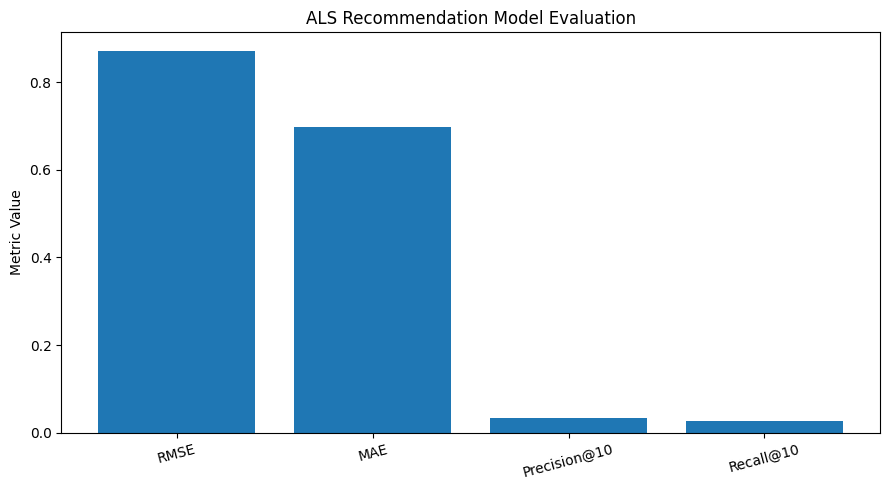

In [38]:
import matplotlib.pyplot as plt

metric_names = ["RMSE", "MAE", "Precision@10", "Recall@10"]
metric_values = [rmse, mae, precision_at_10, recall_at_10]

plt.figure(figsize=(9, 5))
plt.bar(metric_names, metric_values)
plt.title("ALS Recommendation Model Evaluation")
plt.ylabel("Metric Value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()